# Bab 10 — Clustering Techniques

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

## Ringkasan Bab

**Clustering** adalah *unsupervised learning*: mengelompokkan data **tanpa label** sehingga titik dalam satu kelompok mirip satu sama lain dan berbeda dari kelompok lain. Contoh penggunaannya: segmentasi pelanggan, pengelompokan dokumen, kompresi warna gambar, atau eksplorasi awal data.

| No | Resep | Kelas scikit-learn | Ide utama |
|----|-------|--------------------|-----------|
| 1 | Pengantar clustering | `make_blobs` | konsep kemiripan, data dummy |
| 2 | K-Means | `KMeans` | centroid, minimisasi inersia, *elbow method* |
| 3 | Hierarchical clustering | `AgglomerativeClustering`, `scipy` `dendrogram` | penggabungan bertingkat, linkage, dendrogram |
| 4 | DBSCAN | `DBSCAN`, `NearestNeighbors` | cluster berbasis kepadatan, deteksi noise, *k-distance plot* |
| 5 | Metrik evaluasi cluster | silhouette, Davies–Bouldin, ARI | menilai cluster dengan/tanpa label |
| 6 | Memilih algoritma | blobs, moons, circles | bentuk cluster menentukan algoritma |
| 7 | Teknik lanjutan | `SpectralClustering`, `GaussianMixture` | graf kemiripan; *soft clustering* probabilistik |
| 8 | Latihan | Iris, moons, Wine | K-Means + evaluasi, DBSCAN vs K-Means, PCA + GMM |

In [1]:
import warnings
warnings.filterwarnings('ignore')

## Resep 1 — Pengantar Clustering

### Teori
Clustering membutuhkan definisi **kemiripan**. Ada tiga pendekatan besar:
- **Berbasis centroid/prototipe** (K-Means, GMM): setiap cluster diwakili satu "pusat"; titik masuk ke pusat terdekat.
- **Berbasis hubungan/hierarki** (agglomerative): cluster dibangun dengan menggabungkan titik/kelompok yang paling dekat secara bertahap.
- **Berbasis kepadatan** (DBSCAN): cluster adalah daerah padat yang dipisahkan daerah jarang.

Karena hampir semua metode memakai jarak, **scaling** penting (Bab 2 dan 4): fitur bersatuan besar akan mendominasi jarak.

Data dummy dibuat dengan `make_blobs`: 300 titik dari 4 distribusi Gaussian isotropik (simpangan baku 0,6), lalu distandardisasi.

In [2]:
# Load the libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# Create the dataset
X, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)
X = StandardScaler().fit_transform(X)

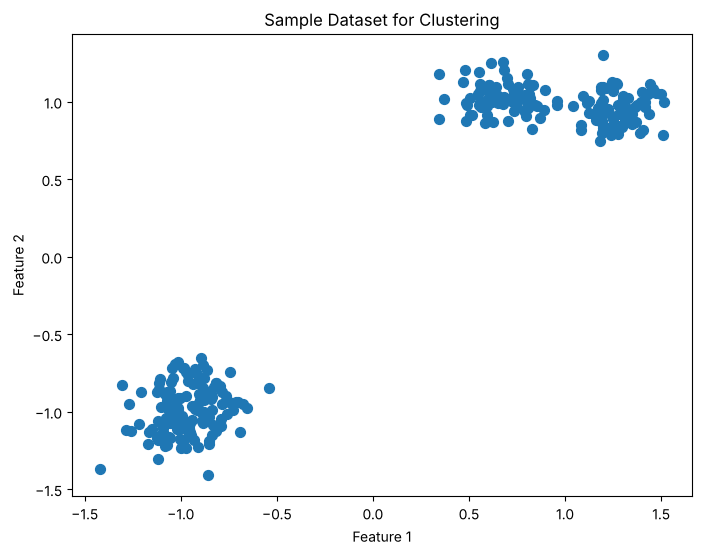

In [3]:
# Visualize the raw data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.title("Sample Dataset for Clustering")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

**Interpretasi.** Plot memperlihatkan struktur yang menarik: 4 gumpalan itu tersusun dalam **dua pasang** — satu pasang di kanan atas (dua gumpalan bersebelahan tetapi masih terpisah) dan satu pasang di kiri bawah yang **saling tumpang tindih**. Jadi walaupun data dibuat dari 4 pusat, struktur yang "terlihat" bisa ditafsirkan sebagai 2, 3, atau 4 cluster. Hal ini akan muncul berulang kali di resep-resep berikutnya dan menjadi pelajaran penting: jumlah cluster "yang benar" sering kali ambigu.

## Resep 2 — K-Means

### Teori
K-Means mencari $K$ centroid $\boldsymbol\mu_1,\dots,\boldsymbol\mu_K$ yang meminimalkan **inersia** (*within-cluster sum of squares*, WCSS):
$$J = \sum_{k=1}^{K}\sum_{\mathbf x_i\in C_k}\lVert\mathbf x_i-\boldsymbol\mu_k\rVert^2$$

**Algoritma Lloyd** (iteratif):
1. **Inisialisasi** $K$ centroid. scikit-learn memakai **k-means++**: centroid pertama dipilih acak, centroid berikutnya dipilih dengan peluang sebanding dengan kuadrat jarak ke centroid terdekat yang sudah ada, sehingga centroid awal tersebar.
2. **Assignment:** setiap titik masuk ke centroid terdekat, $c_i = \arg\min_k\lVert\mathbf x_i-\boldsymbol\mu_k\rVert^2$.
3. **Update:** setiap centroid = rata-rata titik anggotanya, $\boldsymbol\mu_k = \frac{1}{|C_k|}\sum_{\mathbf x_i\in C_k}\mathbf x_i$.
4. Ulangi langkah 2–3 hingga konvergen.

Setiap langkah tidak pernah menaikkan $J$, sehingga algoritma pasti konvergen — tetapi hanya ke **minimum lokal**. Karena itu K-Means dijalankan beberapa kali dengan inisialisasi berbeda (`n_init`) dan hasil dengan inersia terkecil diambil.

**Asumsi implisit:** cluster berbentuk bulat (*convex, isotropic*), ukurannya mirip, dan jumlahnya $K$ diketahui. Batas antar-cluster K-Means selalu berupa garis lurus (diagram Voronoi).

**Elbow method:** plot inersia terhadap $K$. Inersia selalu turun saat $K$ bertambah (dengan $K = n$, inersia = 0), sehingga kita mencari "siku" — titik setelah mana penambahan cluster hanya memberi penurunan kecil.

In [4]:
# Load the libraries
from sklearn.cluster import KMeans
# Reuse the dataset from the previous section
# Dataset already loaded and scaled as X

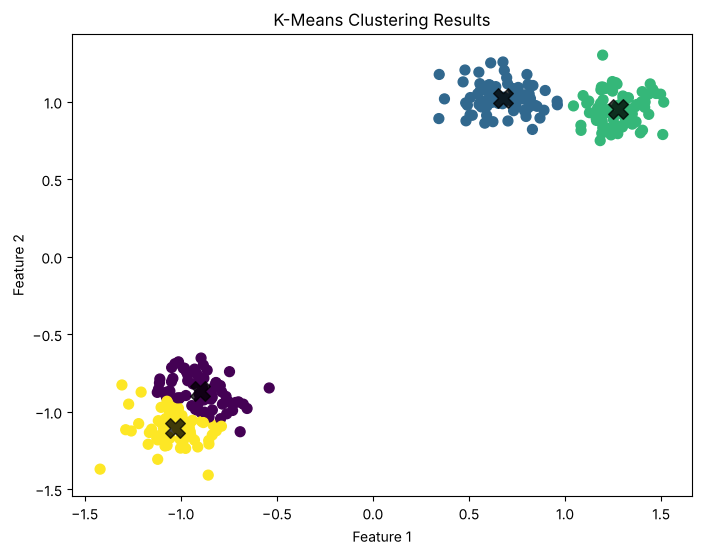

In [5]:
# Apply K-Means clustering
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Plot the clustered data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.75, marker='X')
plt.title("K-Means Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [6]:
print('Inersia (WCSS)      :', round(kmeans.inertia_, 2))
print('Jumlah iterasi      :', kmeans.n_iter_)
print('Ukuran tiap cluster :', np.bincount(y_kmeans))

Inersia (WCSS)      : 7.3
Jumlah iterasi      : 4
Ukuran tiap cluster : [71 77 73 79]


**Interpretasi.** K-Means konvergen hanya dalam 4 iterasi dan membagi data menjadi 4 cluster berukuran 71–79 titik (mendekati 300/4 = 75). Pasangan gumpalan kanan atas dipisahkan dengan rapi. Pasangan kiri bawah yang tumpang tindih juga dibelah dua, tetapi batasnya berupa **garis lurus** (sifat partisi Voronoi K-Means), sehingga sebagian titik dari gumpalan yang satu pasti masuk ke cluster gumpalan lain — K-Means tidak bisa "tahu" titik itu dibangkitkan dari pusat yang mana.

### Elbow method

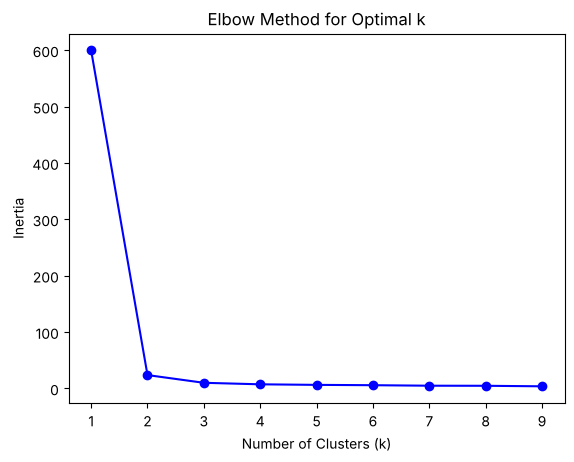

In [7]:
# Calculate and plot clustering inertia
inertia = []
k_values = range(1, 10)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=2024)
    km.fit(X)
    inertia.append(km.inertia_)

plt.plot(k_values, inertia, 'bo-')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal k")
plt.show()

In [8]:
for k, inn in zip(k_values, inertia):
    print(f'k = {k} -> inersia = {inn:8.2f}')

k = 1 -> inersia =   600.00
k = 2 -> inersia =    23.68
k = 3 -> inersia =     9.99
k = 4 -> inersia =     7.30
k = 5 -> inersia =     6.31
k = 6 -> inersia =     5.72
k = 7 -> inersia =     4.83
k = 8 -> inersia =     4.69
k = 9 -> inersia =     3.75


**Interpretasi.** Inersia anjlok dari 600 ($k=1$; sama dengan $n \times p = 300 \times 2$ karena data terstandardisasi) menjadi 23,7 ($k=2$) — penurunan ≈96%. Setelah itu penurunannya kecil: 10,0 ($k=3$), 7,3 ($k=4$), dan terus melandai. "Siku" yang paling tegas ada di **$k=2$**, bukan di $k=4$ seperti jumlah pusat yang dipakai untuk membangkitkan data. Penyebabnya adalah struktur dua pasang gumpalan tadi: jarak antar-pasangan jauh lebih besar daripada jarak di dalam pasangan.

Pelajaran: elbow method memberi **petunjuk**, bukan jawaban pasti. Siku sering tidak tegas, dan pilihan $K$ akhirnya juga bergantung pada tujuan analisis (apakah kita ingin 2 kelompok kasar atau 4 kelompok halus) dan metrik lain seperti silhouette (Resep 5).

## Resep 3 — Hierarchical Clustering

### Teori
**Agglomerative (bottom-up):**
1. Mulai dengan setiap titik sebagai cluster sendiri ($n$ cluster).
2. Gabungkan dua cluster yang paling "dekat".
3. Ulangi sampai tersisa satu cluster (atau sampai jumlah cluster yang diminta).

"Dekat" ditentukan oleh **linkage**:

| Linkage | Jarak antara cluster $A$ dan $B$ | Karakter |
|---|---|---|
| Single | $\min_{a\in A,b\in B} d(a,b)$ | bisa menangkap bentuk memanjang, tetapi rawan "chaining" |
| Complete | $\max_{a\in A,b\in B} d(a,b)$ | cluster kompak |
| Average | rata-rata semua $d(a,b)$ | kompromi |
| **Ward** (default) | kenaikan total varians dalam-cluster jika $A$ dan $B$ digabung: $\Delta = \frac{|A||B|}{|A|+|B|}\lVert\boldsymbol\mu_A-\boldsymbol\mu_B\rVert^2$ | mirip K-Means, cluster bulat berukuran seimbang |

**Dendrogram** adalah pohon yang merekam semua penggabungan; tinggi setiap sambungan = jarak saat dua cluster digabung. Memotong dendrogram secara horizontal pada ketinggian tertentu menghasilkan sejumlah cluster. Celah vertikal yang **panjang** (jarak penggabungan melonjak) menandakan cluster alami yang terpisah jelas.

Kompleksitas naif $O(n^3)$ waktu (atau $O(n^2)$ memori untuk matriks jarak), sehingga kurang cocok untuk data sangat besar.

In [9]:
# Load the libraries
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Reuse the dataset from the earlier section
# Dataset already loaded and scaled as X

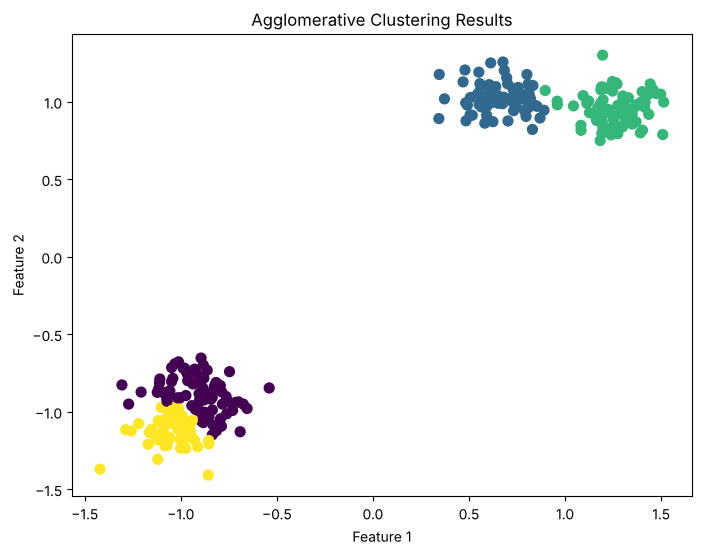

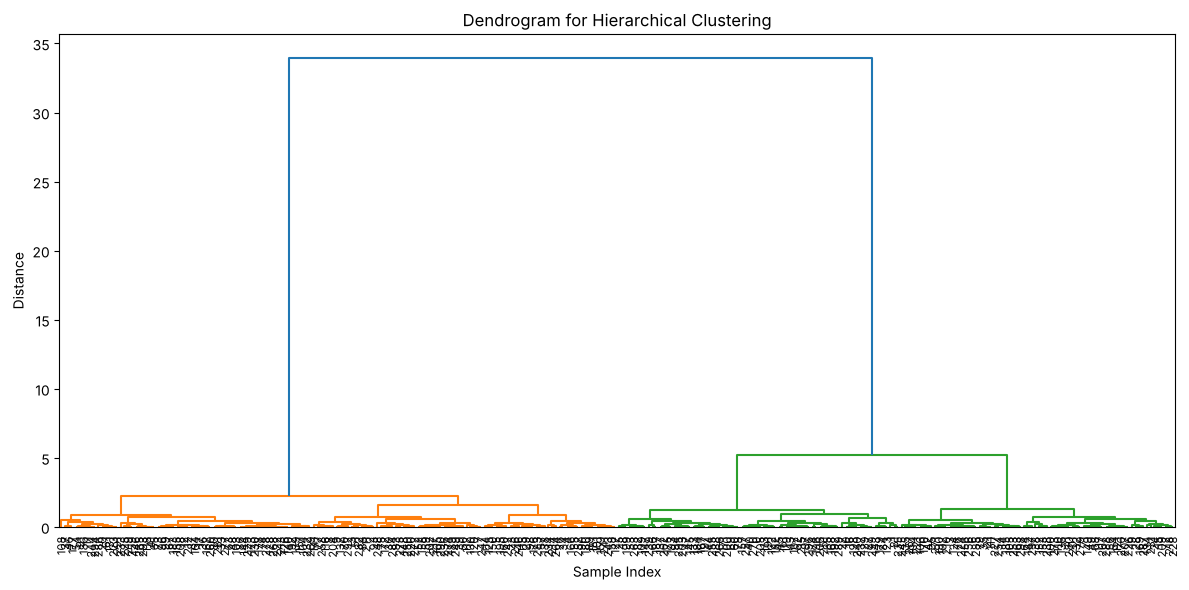

In [10]:
# Apply agglomerative clustering
agg = AgglomerativeClustering(n_clusters=4)
y_agg = agg.fit_predict(X)

# Plot the clustered data
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_agg, cmap='viridis', s=50)
plt.title("Agglomerative Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

# Generate the dendrogram using SciPy
linked = linkage(X, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linked, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrogram for Hierarchical Clustering")
plt.xlabel("Sample Index")
plt.ylabel("Distance")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.metrics import adjusted_rand_score
print('Kecocokan hasil Agglomerative vs K-Means (ARI): %.3f' % adjusted_rand_score(y_kmeans, y_agg))
# 5 tinggi penggabungan terakhir (paling atas di dendrogram)
print('5 jarak penggabungan terakhir:', np.round(linked[-5:, 2], 2))

Kecocokan hasil Agglomerative vs K-Means (ARI): 0.882
5 jarak penggabungan terakhir: [ 1.28  1.58  2.25  5.21 33.95]


**Interpretasi.**
- Agglomerative (Ward) dengan 4 cluster menghasilkan pengelompokan yang **hampir sama** dengan K-Means (ARI ≈ 0,88). Wajar, karena Ward juga meminimalkan varians dalam-cluster seperti K-Means. Perbedaannya terutama ada pada titik-titik di daerah tumpang tindih pasangan kiri bawah.
- **Dendrogram:** lima jarak penggabungan terakhir adalah 1,28 → 1,58 → 2,25 → 5,21 → **33,95**. Lompatan terbesar terjadi pada penggabungan terakhir (5,21 → 33,95), artinya memotong dendrogram di antara keduanya menghasilkan **2 cluster** yang sangat jelas terpisah — konsisten dengan elbow method. Lompatan berikutnya (2,25 → 5,21) mendukung pilihan 3 cluster, dan memotong di bawah 2,25 memberi 4 cluster. Dendrogram memperlihatkan seluruh hierarki ini dalam satu gambar, kelebihan yang tidak dimiliki K-Means.

## Resep 4 — Density-Based Clustering dengan DBSCAN

### Teori
DBSCAN (Ester dkk., 1996) mendefinisikan cluster sebagai daerah **padat**. Dua parameter:
- $\varepsilon$ (`eps`): radius lingkungan.
- `min_samples`: jumlah minimum titik (termasuk dirinya) dalam radius $\varepsilon$ agar suatu titik disebut padat.

Klasifikasi titik:
- **Core point:** $|N_\varepsilon(\mathbf x)| \ge$ `min_samples`.
- **Border point:** bukan core, tetapi berada dalam radius $\varepsilon$ dari sebuah core point.
- **Noise:** bukan keduanya → diberi label **−1**.

Cluster = himpunan titik yang saling **density-reachable** melalui rantai core point. Kelebihan: tidak perlu menentukan jumlah cluster, bisa menemukan cluster berbentuk **sembarang** (bulan sabit, spiral), dan otomatis mendeteksi outlier. Kekurangan: sulit menangani cluster dengan kepadatan yang sangat berbeda (satu $\varepsilon$ untuk semua), dan sensitif terhadap pilihan $\varepsilon$.

**k-distance plot:** untuk setiap titik hitung jarak ke tetangga ke-$k$ ($k$ = `min_samples`), urutkan, dan plot. Titik-titik dalam cluster memiliki jarak kecil; noise memiliki jarak besar. "Siku" pada kurva adalah kandidat $\varepsilon$ yang baik.

### Persiapan — data `make_moons`
Dua bulan sabit yang saling mengait — bentuk yang mustahil dipisahkan K-Means dengan benar.

In [12]:
# Load the libraries
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons

# Create a new one with noise
X, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)

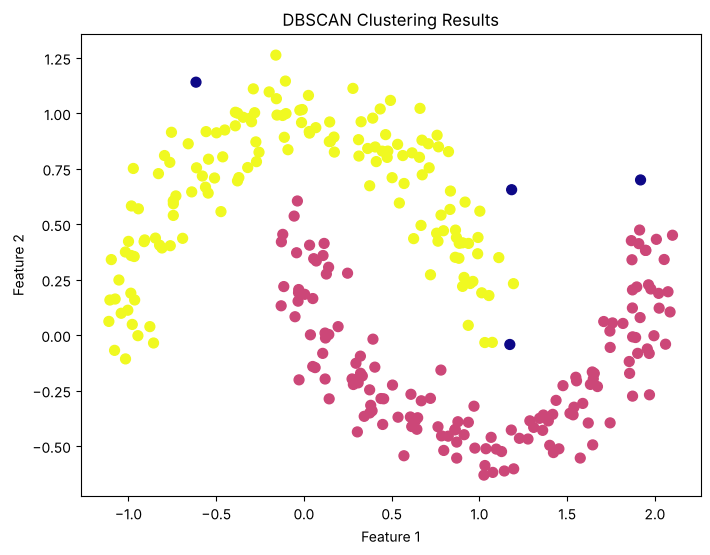

In [13]:
# Apply DBSCAN
dbscan = DBSCAN(eps=0.2, min_samples=5)
y_db = dbscan.fit_predict(X)

# Plot the DBSCAN results
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y_db, cmap='plasma', s=50)
plt.title("DBSCAN Clustering Results")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [14]:
labels_, counts_ = np.unique(y_db, return_counts=True)
print('Label cluster dan jumlah titik:', dict(zip(labels_.tolist(), counts_.tolist())))
print('Jumlah core point:', len(dbscan.core_sample_indices_))

Label cluster dan jumlah titik: {-1: 4, 0: 150, 1: 146}
Jumlah core point: 290


**Interpretasi.** DBSCAN dengan `eps=0.2` dan `min_samples=5` menemukan **2 cluster** (150 dan 146 titik) — tepat dua bulan sabit — tanpa diberi tahu jumlah cluster-nya. Sebanyak **4 titik** diberi label −1 (noise): titik-titik yang terlalu jauh dari tetangganya akibat noise pada data. 290 dari 300 titik adalah core point; sisanya border atau noise. Karena DBSCAN menyambungkan titik lewat rantai tetangga yang padat, ia dapat mengikuti lengkungan bulan sabit — sesuatu yang mustahil bagi K-Means (lihat Latihan 2).

### k-distance plot untuk memilih `eps`

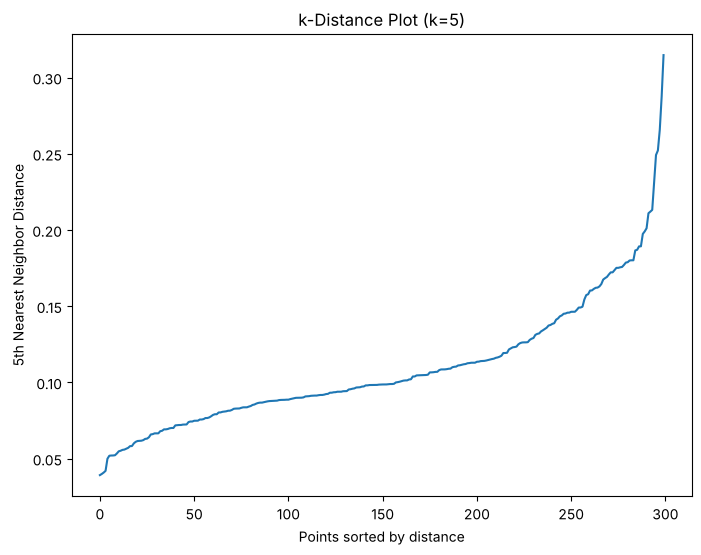

In [15]:
# Load libraries
from sklearn.neighbors import NearestNeighbors

# Generate Nearest Neighbors
neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X)
distances, indices = neighbors_fit.kneighbors(X)
distances = np.sort(distances[:, 4])

# Plot k-distance
plt.figure(figsize=(8, 6))
plt.plot(distances)
plt.title("k-Distance Plot (k=5)")
plt.xlabel("Points sorted by distance")
plt.ylabel("5th Nearest Neighbor Distance")
plt.show()

In [16]:
print('Persentil jarak ke-5 tetangga: 50%% = %.3f | 90%% = %.3f | 95%% = %.3f | maks = %.3f'
      % tuple(np.percentile(distances, [50, 90, 95, 100])))

Persentil jarak ke-5 tetangga: 50% = 0.099 | 90% = 0.169 | 95% = 0.187 | maks = 0.315


**Interpretasi.** Sebagian besar titik memiliki jarak ke tetangga ke-5 yang kecil (median ≈0,10; 95% titik ≤ 0,19), lalu kurva melonjak tajam di ujung kanan hingga ≈0,32. "Siku" kurva berada sekitar **0,15–0,20**, sehingga `eps=0.2` yang dipakai buku memang pilihan yang masuk akal: hampir semua titik cluster memiliki 5 tetangga dalam radius itu, sedangkan beberapa titik di ujung kurva (jarak > 0,2) menjadi kandidat noise — cocok dengan 4 titik noise yang ditemukan.

## Resep 5 — Metrik Evaluasi Cluster

### Teori
Tanpa label, kualitas cluster dinilai dari **struktur internal**:

**Silhouette score.** Untuk titik $i$: $a(i)$ = rata-rata jarak ke titik lain di cluster-nya sendiri; $b(i)$ = rata-rata jarak ke titik di cluster terdekat lainnya.
$$s(i) = \frac{b(i)-a(i)}{\max\{a(i),\,b(i)\}}\in[-1,1]$$
$s \approx 1$: titik jauh lebih dekat ke cluster sendiri; $s\approx 0$: di perbatasan; $s<0$: kemungkinan salah cluster. Skor keseluruhan = rata-rata $s(i)$.

**Davies–Bouldin index** (makin kecil makin baik). Dengan $s_k$ = rata-rata jarak titik ke centroid cluster $k$, dan $d_{kl}$ = jarak antar-centroid:
$$DB = \frac1K\sum_{k=1}^{K}\max_{l\neq k}\frac{s_k+s_l}{d_{kl}}$$

**Calinski–Harabasz** (*variance ratio criterion*, makin besar makin baik): rasio sebaran antar-cluster terhadap sebaran dalam-cluster.

Jika label sebenarnya tersedia (evaluasi **eksternal**):

**Adjusted Rand Index (ARI).** Rand Index menghitung proporsi pasangan titik yang "disepakati" dua pengelompokan (sama-sama satu cluster atau sama-sama beda cluster). ARI mengoreksinya terhadap kesepakatan karena kebetulan:
$$\text{ARI}=\frac{\text{RI}-\mathbb E[\text{RI}]}{\max(\text{RI})-\mathbb E[\text{RI}]}$$
ARI = 1 berarti identik, ≈0 setara pengelompokan acak. ARI tidak peduli nomor label (cluster "0" tidak harus sama dengan kelas "0").

Catatan: metrik internal seperti silhouette dan DB cenderung menyukai cluster bulat (konveks), sehingga bisa menilai rendah hasil DBSCAN yang sebenarnya benar pada data berbentuk bulan sabit.

In [17]:
# Load the libraries
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans

# Generate a labeled dataset for evaluation
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=2024)

# Fit KMeans for use with evaluation metrics
kmeans = KMeans(n_clusters=4, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

In [18]:
# Calculate the silhouette score
sil_score = silhouette_score(X, y_kmeans)
print(f"Silhouette Score: {sil_score:.3f}")

# Calculate the Davies-Bouldin index
db_index = davies_bouldin_score(X, y_kmeans)
print(f"Davies-Bouldin Index: {db_index:.3f}")

# (Optional) Calculate adjusted Rand index if ground truth is known
ari = adjusted_rand_score(y_true, y_kmeans)
print(f"Adjusted Rand Index: {ari:.3f}")

Silhouette Score: 0.534
Davies-Bouldin Index: 0.702
Adjusted Rand Index: 0.814


In [19]:
from sklearn.metrics import calinski_harabasz_score
print('Calinski-Harabasz Index: %.1f' % calinski_harabasz_score(X, y_kmeans))

# Silhouette untuk beberapa nilai k (alternatif elbow method)
for k in range(2, 8):
    lab = KMeans(n_clusters=k, random_state=2024).fit_predict(X)
    print(f'k = {k}: silhouette = {silhouette_score(X, lab):.3f} | Davies-Bouldin = {davies_bouldin_score(X, lab):.3f}')

Calinski-Harabasz Index: 8670.8
k = 2: silhouette = 0.887 | Davies-Bouldin = 0.169
k = 3: silhouette = 0.768 | Davies-Bouldin = 0.390
k = 4: silhouette = 0.534 | Davies-Bouldin = 0.702
k = 5: silhouette = 0.446 | Davies-Bouldin = 0.879
k = 6: silhouette = 0.391 | Davies-Bouldin = 0.966


k = 7: silhouette = 0.400 | Davies-Bouldin = 0.942


**Interpretasi.** Data di resep ini dibangkitkan dengan cara yang sama tetapi **tanpa** standardisasi.
- Dengan $k=4$: silhouette 0,534 (cukup baik), Davies–Bouldin 0,702, dan **ARI 0,814** terhadap label pembangkit. ARI tidak mencapai 1 karena dua gumpalan kiri bawah tumpang tindih — titik di daerah tumpang tindih tidak mungkin dikelompokkan sesuai asalnya.
- Tabel per-$k$ memperlihatkan bahwa silhouette tertinggi (0,887) dan Davies–Bouldin terendah (0,169) justru di **$k=2$**, lalu memburuk seiring bertambahnya $k$. Metrik internal "menyukai" pemisahan yang paling tegas, yaitu dua pasangan gumpalan.

Ini contoh penting perbedaan evaluasi **internal** dan **eksternal**: menurut struktur data, $k=2$ adalah pengelompokan paling bersih; menurut "kebenaran" pembangkit data, ada 4 kelompok. Tidak ada yang salah — keduanya menjawab pertanyaan yang berbeda.

## Resep 6 — Memilih Algoritma Clustering yang Tepat

### Teori
| Algoritma | Bentuk cluster | Perlu $K$? | Menangani noise? | Skala data |
|---|---|---|---|---|
| K-Means | bulat/konveks, ukuran mirip | ya | tidak | sangat besar ($O(nKt)$) |
| Agglomerative (Ward) | bulat | ya (atau ambang jarak) | tidak | kecil–menengah ($O(n^2)$ memori) |
| DBSCAN | sembarang, kepadatan mirip | tidak | **ya** | menengah–besar |
| Spectral | sembarang (berbasis graf) | ya | tidak | kecil–menengah |
| GMM | elips, boleh tumpang tindih | ya | tidak (tetapi memberi probabilitas) | menengah |

Prinsip utama: **visualisasikan data terlebih dulu** (atau proyeksinya dengan PCA/t-SNE dari Bab 3) untuk memahami struktur sebelum memilih algoritma.

In [20]:
# Load the libraries
from sklearn.datasets import make_moons, make_blobs, make_circles
from sklearn.preprocessing import StandardScaler

# Create and scale different datasets
X_blobs, _ = make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)
X_moons, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X_circles, _ = make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)

X_blobs = StandardScaler().fit_transform(X_blobs)
X_moons = StandardScaler().fit_transform(X_moons)
X_circles = StandardScaler().fit_transform(X_circles)

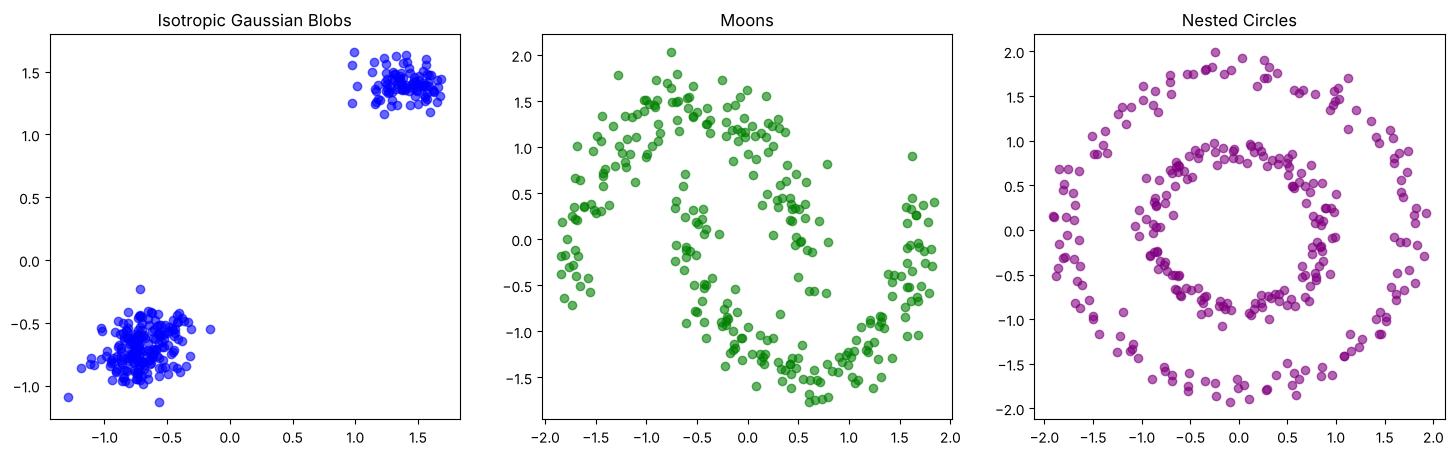

In [21]:
# Visualize the datasets
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].scatter(X_blobs[:, 0], X_blobs[:, 1], c='blue', alpha=0.6)
axs[0].set_title("Isotropic Gaussian Blobs")
axs[1].scatter(X_moons[:, 0], X_moons[:, 1], c='green', alpha=0.6)
axs[1].set_title("Moons")
axs[2].scatter(X_circles[:, 0], X_circles[:, 1], c='purple', alpha=0.6)
axs[2].set_title("Nested Circles")
plt.show()

In [22]:
# Eksperimen tambahan: bandingkan 3 algoritma pada 3 dataset (dengan label asli) menggunakan ARI
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score
datasets = {
    'Blobs':   (X_blobs,   make_blobs(n_samples=300, centers=3, cluster_std=0.6, random_state=2024)[1], 3),
    'Moons':   (X_moons,   make_moons(n_samples=300, noise=0.1, random_state=2024)[1], 2),
    'Circles': (X_circles, make_circles(n_samples=300, noise=0.05, factor=0.5, random_state=2024)[1], 2),
}
rows = []
for name, (Xd, yd, k) in datasets.items():
    rows.append({
        'dataset': name,
        'K-Means': adjusted_rand_score(yd, KMeans(n_clusters=k, random_state=2024).fit_predict(Xd)),
        'Agglomerative (Ward)': adjusted_rand_score(yd, AgglomerativeClustering(n_clusters=k).fit_predict(Xd)),
        'Agglomerative (single)': adjusted_rand_score(yd, AgglomerativeClustering(n_clusters=k, linkage='single').fit_predict(Xd)),
        'DBSCAN (eps=0.3)': adjusted_rand_score(yd, DBSCAN(eps=0.3, min_samples=5).fit_predict(Xd)),
    })
display(pd.DataFrame(rows).set_index('dataset').round(3))

,K-Means,Agglomerative (Ward),Agglomerative (single),DBSCAN (eps=0.3)
dataset,,,,
Blobs,0.644,0.552,0.569,0.570
Moons,0.507,0.470,0.000,0.948
Circles,-0.003,-0.003,1.000,1.000


**Interpretasi.** Tabel ARI di atas (1 = sempurna, 0 ≈ acak) merangkum seluruh resep ini:
- **Circles:** K-Means dan Ward gagal total (ARI ≈ 0) karena keduanya hanya bisa membuat batas lurus/cluster bulat, sedangkan lingkaran dalam berada **di tengah** lingkaran luar. DBSCAN dan single linkage berhasil sempurna (ARI = 1) karena keduanya mengikuti rantai titik yang berdekatan.
- **Moons:** DBSCAN unggul jauh (0,948); K-Means dan Ward hanya ≈0,5. Single linkage gagal (0,000) karena noise membuat ada "jembatan" titik di antara dua bulan sabit — efek *chaining*: 299 titik tersambung menjadi satu cluster besar dan cluster kedua hanya berisi **1** titik terpencil.
- **Blobs:** K-Means terbaik (0,644). Nilainya tidak setinggi yang diduga karena dua dari tiga pusat gumpalan dengan `random_state=2024` hanya berjarak ≈1,3 satuan (sementara pusat ketiga berjarak ≈14–15), sehingga dua gumpalan itu tumpang tindih dan sebagian titiknya tidak bisa dikelompokkan sesuai asalnya.

Kesimpulan: **bentuk data menentukan algoritma**, persis seperti yang dirangkum di tabel teori.

## Resep 7 — Teknik Clustering Lanjutan

### Teori

**Spectral Clustering.**
1. Bangun **graf kemiripan**: setiap titik adalah simpul; bobot sisi $W_{ij}$ menyatakan kemiripan (di sini `affinity='nearest_neighbors'`: terhubung jika termasuk tetangga terdekat).
2. Hitung **graph Laplacian** $L = D - W$ (atau versi ternormalisasi), dengan $D$ matriks diagonal derajat simpul.
3. Ambil $K$ **vektor eigen** dengan nilai eigen terkecil dari $L$ → setiap titik mendapat representasi baru berdimensi $K$.
4. Jalankan K-Means pada representasi baru itu.

Intuisinya: clustering dijadikan masalah **memotong graf** menjadi bagian-bagian dengan sisi antar-bagian sesedikit mungkin (*normalized cut*). Dua titik di ujung bulan sabit yang sama terhubung melalui rantai tetangga, sehingga berada di bagian graf yang sama walaupun jarak Euclidean-nya jauh.

**Gaussian Mixture Model (GMM).** Data diasumsikan berasal dari campuran $K$ distribusi Gaussian:
$$p(\mathbf x) = \sum_{k=1}^{K}\pi_k\,\mathcal N(\mathbf x\mid\boldsymbol\mu_k,\boldsymbol\Sigma_k),\qquad \sum_k\pi_k = 1$$
Parameter dicari dengan algoritma **Expectation–Maximization (EM)**:
- **E-step:** hitung *responsibility* $\gamma_{ik} = \dfrac{\pi_k\,\mathcal N(\mathbf x_i\mid\boldsymbol\mu_k,\boldsymbol\Sigma_k)}{\sum_j\pi_j\,\mathcal N(\mathbf x_i\mid\boldsymbol\mu_j,\boldsymbol\Sigma_j)}$ = peluang titik $i$ berasal dari komponen $k$.
- **M-step:** perbarui $\pi_k$, $\boldsymbol\mu_k$, $\boldsymbol\Sigma_k$ sebagai rata-rata tertimbang dengan bobot $\gamma_{ik}$.

GMM adalah **soft clustering** (setiap titik punya probabilitas keanggotaan, `predict_proba`) dan dengan kovarians penuh bisa memodelkan cluster **berbentuk elips**. K-Means dapat dipandang sebagai kasus khusus GMM dengan kovarians $\sigma^2\mathbf I$ yang sama dan penugasan "keras". Jumlah komponen dapat dipilih dengan **BIC/AIC**.

In [23]:
# Load the libraries
from sklearn.cluster import SpectralClustering
from sklearn.mixture import GaussianMixture
# Create datasets with complex structure
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

X, _ = make_moons(n_samples=300, noise=0.05, random_state=2024)
X = StandardScaler().fit_transform(X)

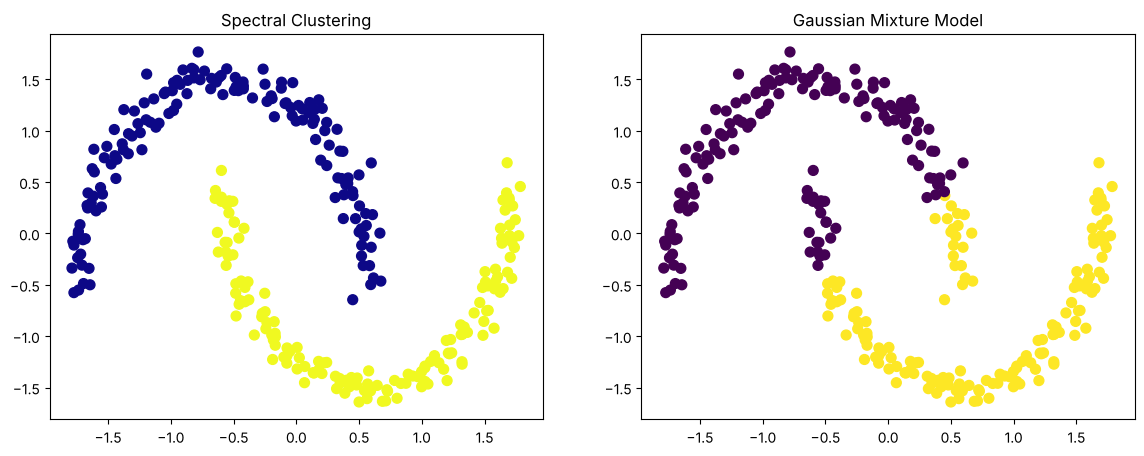

In [24]:
# Apply Spectral Clustering
spectral = SpectralClustering(n_clusters=2, affinity='nearest_neighbors', random_state=2024)
y_spectral = spectral.fit_predict(X)

# Apply Gaussian Mixture Model
gmm = GaussianMixture(n_components=2, random_state=2024)
y_gmm = gmm.fit_predict(X)

# Visualize both clustering results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_spectral, cmap='plasma', s=50)
ax1.set_title("Spectral Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_gmm, cmap='viridis', s=50)
ax2.set_title("Gaussian Mixture Model")

plt.show()

In [25]:
y_true_moons = make_moons(n_samples=300, noise=0.05, random_state=2024)[1]
print('ARI Spectral Clustering: %.3f' % adjusted_rand_score(y_true_moons, y_spectral))
print('ARI Gaussian Mixture   : %.3f' % adjusted_rand_score(y_true_moons, y_gmm))

proba = gmm.predict_proba(X)
uncertain = np.sum(proba.max(axis=1) < 0.9)
print('Titik dengan probabilitas keanggotaan GMM < 0.9: %d dari %d' % (uncertain, len(X)))

ARI Spectral Clustering: 1.000
ARI Gaussian Mixture   : 0.526
Titik dengan probabilitas keanggotaan GMM < 0.9: 40 dari 300


**Interpretasi.**
- **Spectral Clustering: ARI = 1,000** — kedua bulan sabit dipisahkan sempurna. Graf tetangga terdekat menghubungkan titik-titik di sepanjang setiap bulan sabit, dan hampir tidak ada sisi yang menyeberang antar-bulan, sehingga pemotongan graf menjadi dua bagian jatuh tepat di antara keduanya.
- **GMM: ARI ≈ 0,53** — GMM memodelkan setiap cluster sebagai satu elips Gaussian. Bulan sabit tidak berbentuk elips, sehingga GMM membelah data dengan batas yang hampir lurus (mirip K-Means) dan memotong kedua bulan sabit.
- Kelebihan GMM tetap terlihat: 40 dari 300 titik memiliki probabilitas keanggotaan < 0,9. GMM "tahu" bahwa titik-titik ini ambigu — informasi yang tidak diberikan K-Means. Untuk data bulan sabit, GMM dengan lebih banyak komponen (misalnya 6–8 komponen, lalu digabungkan) atau DBSCAN/Spectral lebih tepat.

## Latihan Praktik

### Latihan 1 — K-Means pada dataset Iris

Silhouette Score: 0.553
Adjusted Rand Index: 0.730


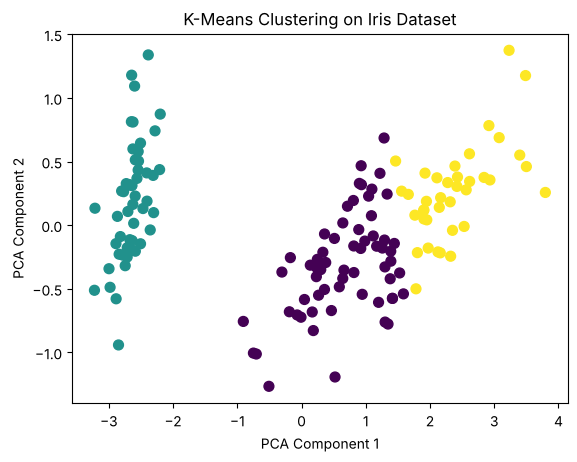

In [26]:
# Load libraries
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
import matplotlib.pyplot as plt

# Load the Dataset
iris = load_iris()
X = iris.data
y_true = iris.target

# Create and Train the KMeans Model
kmeans = KMeans(n_clusters=3, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

# Evaluate the Clustering
sil_score = silhouette_score(X, y_kmeans)
ari = adjusted_rand_score(y_true, y_kmeans)

print(f"Silhouette Score: {sil_score:.3f}")
print(f"Adjusted Rand Index: {ari:.3f}")

# Visualize the Cluster Assignments (PCA Projection)
from sklearn.decomposition import PCA

X_pca = PCA(n_components=2).fit_transform(X)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_kmeans, cmap='viridis', s=50)
plt.title("K-Means Clustering on Iris Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [27]:
import pandas as pd
print('Tabel silang cluster K-Means vs spesies sebenarnya:')
display(pd.crosstab(pd.Series(iris.target_names[y_true], name='spesies'), pd.Series(y_kmeans, name='cluster')))

Tabel silang cluster K-Means vs spesies sebenarnya:


cluster,0,1,2
spesies,,,
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


**Interpretasi.** Silhouette 0,553 dan ARI 0,730. Tabel silang menjelaskan angka ARI tersebut:
- Semua 50 *setosa* masuk ke satu cluster yang murni — *setosa* terpisah jelas dari spesies lain (seperti yang terlihat sejak Bab 3 dan 6).
- *Versicolor* hampir semuanya (48) masuk satu cluster, tetapi cluster itu juga menyerap **14 virginica**; sisanya 36 virginica membentuk cluster sendiri bersama 2 versicolor.

Jadi K-Means **tanpa melihat label** sudah menemukan struktur spesies dengan cukup baik, dan kesalahannya kembali terjadi di pasangan *versicolor–virginica* yang memang tumpang tindih. Pada plot PCA, cluster *setosa* (kiri) terpisah jauh, sedangkan dua cluster lain bersebelahan dengan batas lurus di antaranya.

### Latihan 2 — DBSCAN vs K-Means pada data moons

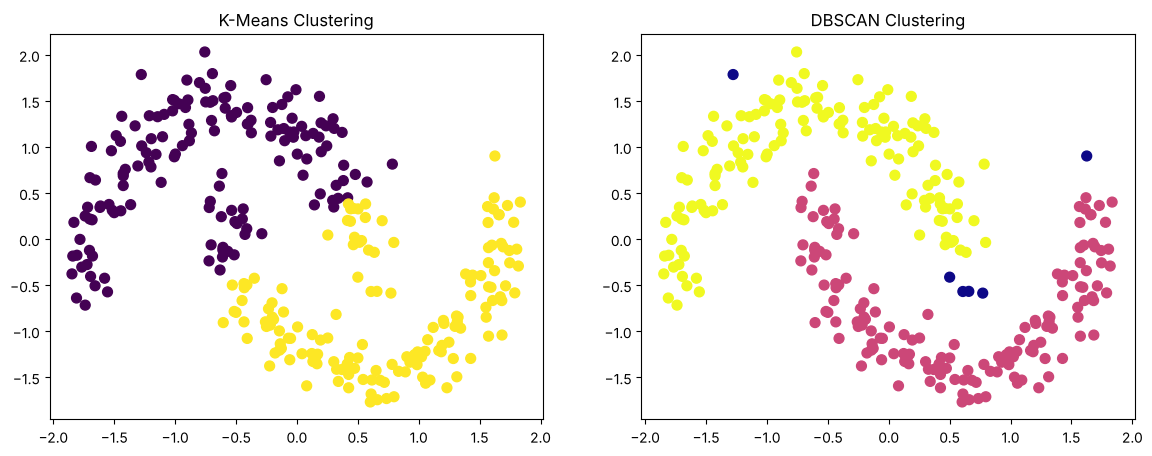

In [28]:
# Load libraries
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN, KMeans
import matplotlib.pyplot as plt

# Create and Scale the Dataset
X, _ = make_moons(n_samples=300, noise=0.1, random_state=2024)
X = StandardScaler().fit_transform(X)

# Apply KMeans and DBSCAN
kmeans = KMeans(n_clusters=2, random_state=2024)
y_kmeans = kmeans.fit_predict(X)

dbscan = DBSCAN(eps=0.3, min_samples=5)
y_dbscan = dbscan.fit_predict(X)

# Visualize the Clustering Results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(X[:, 0], X[:, 1], c=y_kmeans, cmap='viridis', s=50)
ax1.set_title("K-Means Clustering")

ax2.scatter(X[:, 0], X[:, 1], c=y_dbscan, cmap='plasma', s=50)
ax2.set_title("DBSCAN Clustering")

plt.show()

In [29]:
y_true_ex2 = make_moons(n_samples=300, noise=0.1, random_state=2024)[1]
print('ARI K-Means: %.3f' % adjusted_rand_score(y_true_ex2, y_kmeans))
print('ARI DBSCAN : %.3f' % adjusted_rand_score(y_true_ex2, y_dbscan))
print('Label DBSCAN:', dict(zip(*[a.tolist() for a in np.unique(y_dbscan, return_counts=True)])))

ARI K-Means: 0.507
ARI DBSCAN : 0.948
Label DBSCAN: {-1: 6, 0: 150, 1: 144}


**Interpretasi.** Pada data yang sama (moons, terstandardisasi), **DBSCAN** mencapai ARI 0,948 — dua bulan sabit dikenali dengan benar dan 6 titik ditandai noise. **K-Means** hanya 0,507: ia membelah data dengan satu garis lurus sehingga setiap cluster berisi sebagian dari kedua bulan sabit. Perhatikan bahwa `eps` di sini 0,3 (bukan 0,2 seperti Resep 4) karena data sudah distandardisasi sehingga jarak antar-titik berubah skala — `eps` harus selalu disesuaikan dengan skala data.

### Latihan 3 — PCA + GMM pada dataset Wine

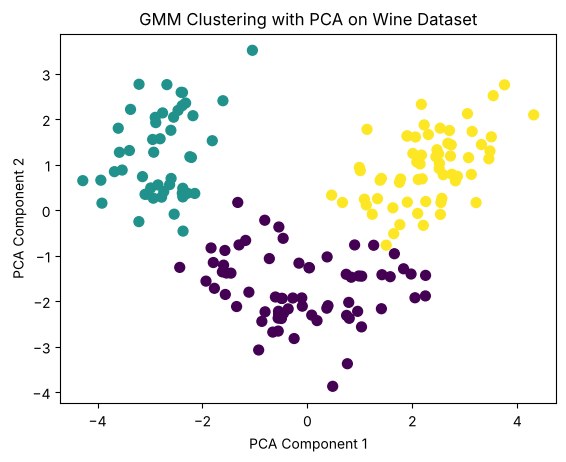

In [30]:
# Load libraries
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

# Load and Preprocess the Dataset
data = load_wine()
X = StandardScaler().fit_transform(data.data)

# Apply PCA for Dimensionality Reduction
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Fit Gaussian Mixture Model
gmm = GaussianMixture(n_components=3, random_state=2024)
y_gmm = gmm.fit_predict(X_pca)

# Visualize the Clustered Output
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_gmm, cmap='viridis', s=50)
plt.title("GMM Clustering with PCA on Wine Dataset")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

In [31]:
print('Varians yang dijelaskan 2 komponen PCA: %.1f%%' % (100 * pca.explained_variance_ratio_.sum()))
print('ARI GMM vs kultivar sebenarnya: %.3f' % adjusted_rand_score(data.target, y_gmm))
for k in range(1, 7):
    g = GaussianMixture(n_components=k, random_state=2024).fit(X_pca)
    print(f'  n_components = {k}: BIC = {g.bic(X_pca):7.1f}')

Varians yang dijelaskan 2 komponen PCA: 55.4%
ARI GMM vs kultivar sebenarnya: 0.914
  n_components = 1: BIC =  1474.8
  n_components = 2: BIC =  1338.8
  n_components = 3: BIC =  1313.4
  n_components = 4: BIC =  1328.7
  n_components = 5: BIC =  1341.8


  n_components = 6: BIC =  1365.3


**Interpretasi.**
- Dua komponen PCA hanya menjelaskan 55,4% varians Wine (sama seperti Bab 3), tetapi cukup untuk memisahkan ketiga kultivar: GMM mencapai **ARI 0,914** terhadap label sebenarnya, padahal tidak pernah melihat label.
- **BIC** (*Bayesian Information Criterion*, $\text{BIC} = -2\log\hat L + m\log n$, dengan $m$ = jumlah parameter) menyeimbangkan kecocokan model dengan kompleksitasnya; makin kecil makin baik. BIC minimum ada di **3 komponen** (1.313,4) — tepat jumlah kultivar. Ini contoh cara memilih jumlah cluster secara prinsipil dengan model probabilistik, sebagai alternatif elbow method.

## Kesimpulan Bab 10

- **K-Means** meminimalkan inersia dengan algoritma Lloyd + inisialisasi k-means++; cepat, tetapi mengasumsikan cluster bulat dan butuh $K$ (pilih dengan elbow atau silhouette).
- **Agglomerative** menggabungkan cluster bertahap sesuai *linkage*; dendrogram membantu memilih jumlah cluster. Ward ≈ K-Means; single linkage bisa mengikuti bentuk memanjang.
- **DBSCAN** menemukan cluster berbentuk sembarang berdasarkan kepadatan dan menandai noise sebagai −1; parameter `eps` dipilih dengan k-distance plot.
- **Spectral clustering** memakai graf kemiripan; **GMM** memberi keanggotaan probabilistik dan cluster berbentuk elips.
- **Evaluasi:** silhouette (↑), Davies–Bouldin (↓), Calinski–Harabasz (↑) tanpa label; ARI jika label tersedia. Metrik internal menyukai cluster bulat, jadi selalu lengkapi dengan visualisasi.
- Tidak ada algoritma terbaik untuk semua data — bentuk data menentukan pilihan algoritma.